## Задание 1

Интерполяционно-характеристическим методом получить конечно-разностную
схему с заданным шаблоном. Варианты шаблонов приведены на рисунке 1 на второй странице.


В нашей схеме считаем данными узлы $(i-1, n),\ (i,n),\ (i, n-1)$, а пытаемся определить мы $(i,n+1)$. $i$ - координаты, $n$ - времена. Перенесем все узловые точки на один временной уровень для того, чтобы решить задачу интерполяции. Перенос осуществляется по определению характеристических линий (вдоль этих линий решение остается одним и тем же). Для линнейного уравнения переноса:
$$u_t +cu_x=0$$
Характеристиками являются линии $x=ct+\text{const}$. Через узловые точки: $x_{n+j}=x_{n}+jc\Delta=x_n+jCh,\ C- $ число Курранта, тогда перенесем все узлы о которых у нас есть информация на один временной уровень $n$, получатся точки: $x(-1) = x_{i-1,n},\ x(0) = x_{i,n}, x(С) = x_{i,n-1},\ x(-С) = x_{i,n+1}$. Решение неизвестно в точке $x(-С)$, из необходимости попадения в интервал интерполяции получаем необходимое условие $C<1$. Теперь представляем полиномиальную зависимость решения в неизвестной точке и находим коэфициенты полинома используя 3 интерполянционные точки, для удобства введем $\psi(x) = (x-x_i)/h$:
$$u(\psi) = a_0+a_1\psi+a_2\psi^2$$
$u(0) = u^n_i= a_0, \ u(-1) = u^n_{i-1} = a_0-a_1+a_2,\ u(C) = u^{n-1}_i=a_0+Ca_1+C^2a_2$. Отсюда $u(\psi)=u^n_i+(\frac{u^{n-1}_i+cu^n_{i-1}}{C^2+C}+u^n_i-u^n_{i-1})\psi+\frac{u^{n-1}_i+Cu^n_{i-1}+(1-C)u^n_i}{C^2+C}\psi^2$. Или, преобразовав выражение и выразив решение для нужной точки:
$$
u(-C)=u^{n+1}_i
=\frac{2C^2}{1+C}\,u^n_{i-1}+2(1-C)\,u^n_i-\frac{1-C}{1+C}\,u^{n-1}_i.
$$

## Задание 2

Реализовать эту схему в программном коде с помощью произвольного языка
программирования для решения линейного уравнения переноса

In [43]:
import numpy as np
import matplotlib.pyplot as plt

def exact(x, n):
    s = x - C * h * n
    return np.exp(-(s - 1)**2 / 2) + 2 * np.exp(-(s - 2)**2 / 2)

def calc(u, u_prev, periodic):
    j = 0 if periodic else 1
    new = np.empty(len(u) - j)
    for i in range(j, len(u)):
        new[i - j] = (
            2 * C**2 / (1 + C) * u[i - 1]
            + 2 * (1 - C) * u[i]
            - (1 - C) / (1 + C) * u_prev[i]
        )
    return new

C = 0.5
x = np.linspace(-4, 6, 101)
h = x[1] - x[0]
n_steps = 100

u_prev = exact(x, 0)
u = exact(x, 1)
out = [u_prev, u]

for n in range(2, n_steps + 1):
    u_next = np.empty_like(u)
    u_next[0] = exact(x[0], n)
    u_next[1:] = calc(u, u_prev, False)
    u_prev, u = u, u_next
    out.append(u.copy())

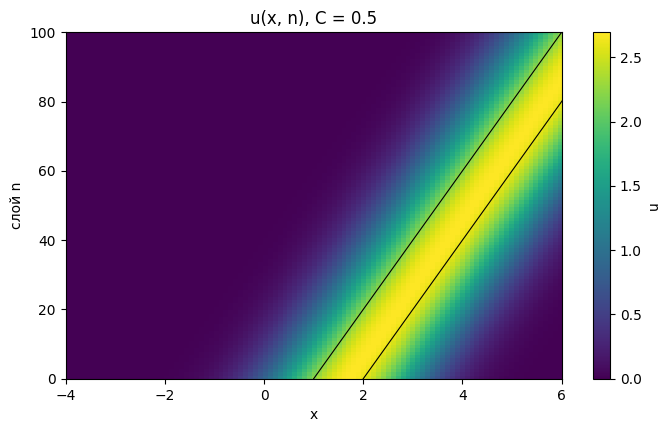

In [44]:
import plotly.graph_objects as go

U = np.asarray(out)
n = np.arange(U.shape[0])

fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(
    U, origin="lower", aspect="auto",
    extent=[x[0], x[-1], n[0], n[-1]],
    cmap="viridis",
)
for x0 in (1, 2):
    ax.plot(x0 + n * C * h, n, color="k", lw=0.8)
ax.set_xlim(x[0], x[-1])
ax.set_xlabel("x")
ax.set_ylabel("слой n")
ax.set_title(f"u(x, n), C = {C}")

fig.colorbar(im, ax=ax, label="u")
plt.show()

fig3 = go.Figure(go.Surface(x=x, y=n, z=U, colorscale="Viridis", colorbar=dict(title="u")))
fig3.update_layout(
    title=f"u(x, n), C = {C}",
    scene=dict(xaxis_title="x", yaxis_title="слой n", zaxis_title="u"),
    width=800, height=600, margin=dict(l=0, r=0, t=40, b=0),
)
fig3.show()

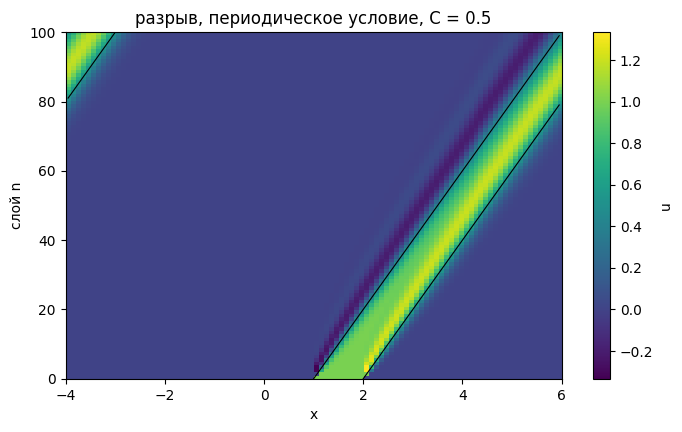

In [45]:
import plotly.graph_objects as go

def rect(z):
    return ((z >= 1) & (z < 2)).astype(float)
x = np.linspace(0.5,2.5,101)
L = 10.0
N = 100
h_p = L / N
x_p = -4 + np.arange(N) * h_p

def exact_p(z, n):
    s = x_p[0] + np.mod(z - x_p[0] - C * h_p * n, L)
    return rect(s)

n_steps = 100
u_prev = exact_p(x_p, 0)
u = exact_p(x_p, 1)
out_p = [u_prev, u]
for n in range(2, n_steps + 1):
    u_next = calc(u, u_prev, True)
    u_prev, u = u, u_next
    out_p.append(u.copy())

U = np.asarray(out_p)
n_ax = np.arange(U.shape[0])

fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(
    U, origin="lower", aspect="auto",
    extent=[x_p[0], x_p[0] + L, n_ax[0], n_ax[-1]],
    cmap="viridis",
)
for x0 in (1, 2):
    y = x_p[0] + np.mod(x0 + n_ax * C * h_p - x_p[0], L)
    y = y.astype(float)
    y[np.where(np.diff(y) < -L / 2)[0] + 1] = np.nan
    ax.plot(y, n_ax, color="k", lw=0.8)
ax.set_xlim(x_p[0], x_p[0] + L)
ax.set_xlabel("x")
ax.set_ylabel("слой n")
ax.set_title(f"разрыв, периодическое условие, C = {C}")
fig.colorbar(im, ax=ax, label="u")
plt.show()

fig3 = go.Figure(go.Surface(x=x_p, y=n_ax, z=U, colorscale="Viridis", colorbar=dict(title="u")))
fig3.update_layout(
    title=f"разрыв, периодическое условие, C = {C}",
    scene=dict(xaxis_title="x", yaxis_title="слой n", zaxis_title="u"),
    width=800, height=600, margin=dict(l=0, r=0, t=40, b=0),
)
fig3.show()

[0. 1.]


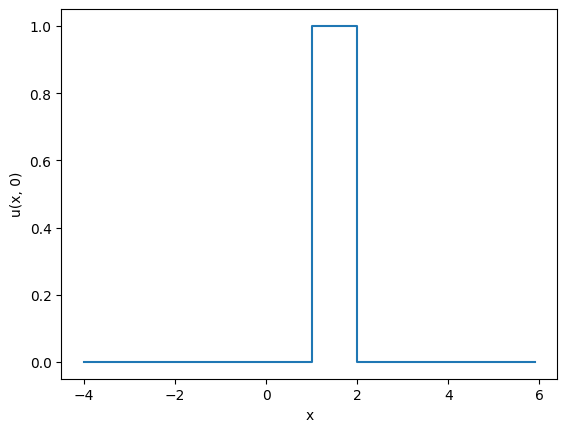

In [46]:
print(np.unique(out_p[0]))  # [0. 1.]

plt.step(x_p, out_p[0], where="post")
plt.xlabel("x")
plt.ylabel("u(x, 0)")
plt.show()

## Задание 4 

Проанализировать используемую конечно-разностную схему. Определить порядок
точности, найти первое дифференциальное приближение, вывести характеристическое уравнение,
построить диссипативную и дисперсионную поверхности.

Рассматривается уравнение переноса $u_t+c u_x=0$, где $c>0$.
Обозначим шаг по времени через $\tau$, шаг по пространству через $h$,
а число Куранта через $C=c\tau/h$. Полученная разностная схема имеет вид

$$
u_i^{n+1}=A u_{i-1}^n+B u_i^n-q u_i^{n-1},
\qquad
A=\frac{2C^2}{1+C},\quad B=2(1-C),\quad q=\frac{1-C}{1+C}.
$$

### Порядок аппроксимации и первое дифференциальное приближение

При $0<C<1$ приведём схему к виду

$$
\frac{1+C}{2C}\frac{u_i^{n+1}-u_i^n}{\tau}
-\frac{1-C}{2C}\frac{u_i^n-u_i^{n-1}}{\tau}
+c\frac{u_i^n-u_{i-1}^n}{h}=0.
$$

Подставим гладкое точное решение и разложим значения в узлах вокруг
$(x_i,t_n)$. При фиксированном $C$ левая часть принимает вид

$$
u_t+c u_x
+\frac{\tau}{2C}u_{tt}-\frac{ch}{2}u_{xx}
+\frac{\tau^2}{6}u_{ttt}+\frac{ch^2}{6}u_{xxx}
+O(h^3).
$$

Из уравнения переноса следуют $u_{tt}=c^2u_{xx}$ и
$u_{ttt}=-c^3u_{xxx}$. Поскольку $\tau/C=h/c$, члены первого порядка
сокращаются. Ведущий член погрешности равен

$$
\frac{ch^2}{6}(1-C^2)u_{xxx}.
$$

Таким образом, схема имеет второй порядок аппроксимации при
$\tau=Ch/c$. Первое дифференциальное приближение имеет вид

$$
\boxed{u_t+c u_x=-\frac{ch^2}{6}(1-C^2)u_{xxx}.}
$$

### Характеристическое уравнение

Для анализа по фон Нейману представим отдельную пространственную
гармонику в виде $u_i^n=g^n e^{\mathrm{i}i\theta}$, где $\theta=kh$,
а $g$ — множитель перехода на следующий временной слой.
Подстановка в разностную схему даёт

$$
\boxed{g^2-\bigl(B+A e^{-\mathrm{i}\theta}\bigr)g+q=0.}
$$

При $\theta=0$ корни равны $1$ и $q$. Физическую ветвь $g_{\rm phys}$
получаем непрерывным продолжением корня $1$ по $\theta$.
Второй корень $g_{\rm par}=q/g_{\rm phys}$ задаёт паразитную ветвь.

### Диссипативная и дисперсионная поверхности

Пусть $g=|g|e^{\mathrm{i}\varphi}$. За один временной шаг амплитуда
гармоники умножается на $|g|$, а её фаза меняется на $\varphi$.
Поэтому для каждой ветви строим две поверхности:

- **Диссипативная** — $|g(C,\theta)|$. Значение меньше единицы
  соответствует затуханию гармоники, больше единицы — её росту.
- **Дисперсионная** — $\displaystyle c_{\rm ph}/c=-\arg g/(C\theta)$.
  Точный перенос даёт фазовый сдвиг $-C\theta$, поэтому для точного
  решения $c_{\rm ph}/c=1$. Зависимость этого отношения от $\theta$
  показывает, что гармоники с разными длинами волн движутся с разными
  фазовыми скоростями.

Достаточно построить поверхности при $0\leq\theta\leq\pi$:
при смене знака $\theta$ корни переходят в комплексно сопряжённые.
В точке $\theta=0$ для отношения фазовых скоростей берём предел.

Максимум |g_phys| на сетке: 1.000000
Максимум |g_par| на сетке:  0.980196


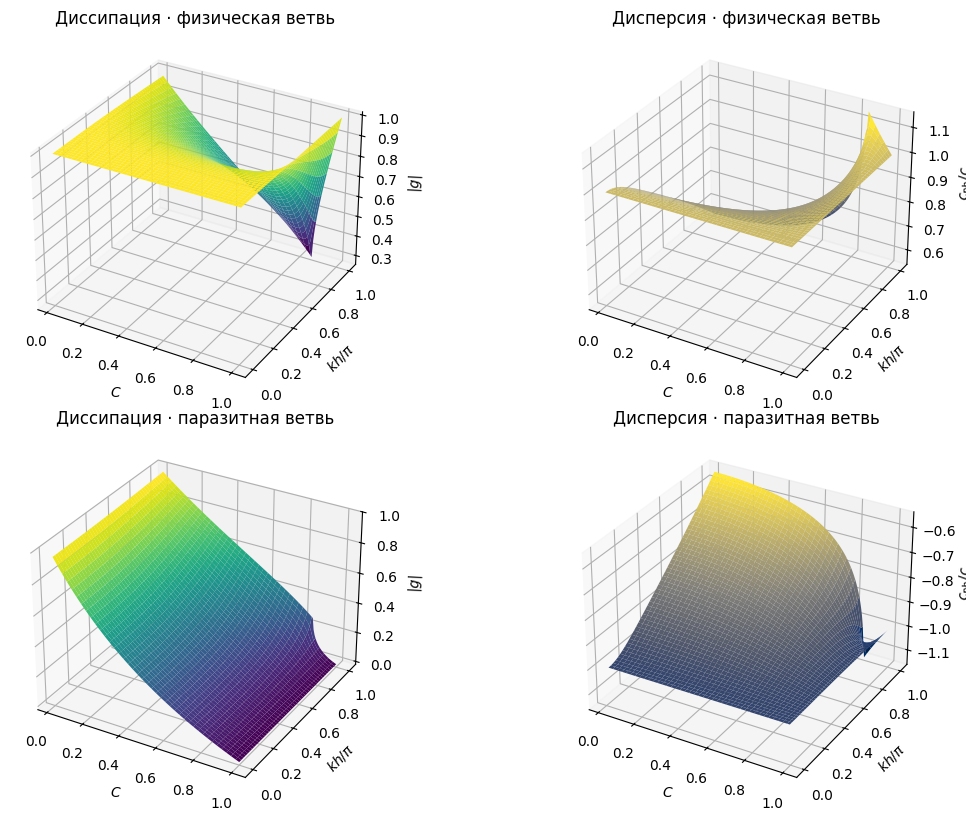

In [47]:
import numpy as np
import matplotlib.pyplot as plt

courant_values = np.linspace(0.02, 1.0, 160)
theta_values = np.linspace(0.0, np.pi, 241)
courant, theta = np.meshgrid(courant_values, theta_values, indexing="ij")

A = 2 * courant**2 / (1 + courant)
B = 2 * (1 - courant)
q = (1 - courant) / (1 + courant)
M = B + A * np.exp(-1j * theta)

# Продолжаем корень дискриминанта от theta = 0 вдоль каждой строки.
discriminant = M**2 - 4 * q
discriminant_phase = np.unwrap(np.angle(discriminant), axis=1)
sqrt_discriminant = np.sqrt(np.abs(discriminant)) * np.exp(
    0.5j * discriminant_phase
)
g_phys = (M + sqrt_discriminant) / 2
g_par = q / g_phys

phase_phys = np.unwrap(np.angle(g_phys), axis=1)
gamma_phys = np.ones_like(theta)  # Предел при theta -> 0.
gamma_phys[:, 1:] = -phase_phys[:, 1:] / (courant * theta)[:, 1:]
gamma_par = np.where(courant < 1, -gamma_phys, np.nan)

np.testing.assert_allclose(g_phys[:, 0], 1, atol=1e-12)
np.testing.assert_allclose(g_par[:, 0], q[:, 0], atol=1e-12)
np.testing.assert_allclose(g_phys[-1], np.exp(-1j * theta_values), atol=1e-12)
for g in (g_phys, g_par):
    np.testing.assert_allclose(g**2 - M * g + q, 0, atol=1e-12)

print(f"Максимум |g_phys| на сетке: {np.abs(g_phys).max():.6f}")
print(f"Максимум |g_par| на сетке:  {np.abs(g_par).max():.6f}")

fig, axes = plt.subplots(
    2, 2, figsize=(11, 8), subplot_kw={"projection": "3d"},
    layout="constrained",
)
panels = [
    (np.abs(g_phys), "Диссипация · физическая ветвь", r"$|g|$", "viridis"),
    (gamma_phys, "Дисперсия · физическая ветвь", r"$c_{\mathrm{ph}}/c$", "cividis"),
    (np.abs(g_par), "Диссипация · паразитная ветвь", r"$|g|$", "viridis"),
    (gamma_par, "Дисперсия · паразитная ветвь", r"$c_{\mathrm{ph}}/c$", "cividis"),
]
for ax, (values, title, zlabel, cmap) in zip(axes.flat, panels):
    ax.plot_surface(courant, theta / np.pi, values, cmap=cmap)
    ax.set(title=title, xlabel=r"$C$", ylabel=r"$kh/\pi$", zlabel=zlabel)

plt.show()

### Устойчивость и выводы

Для $0<C<1$ устойчивость по фон Нейману можно подтвердить аналитически.
Обозначим $M=B+A e^{-\mathrm{i}\theta}$. Из характеристического
уравнения следует $M=g+q/g$. Если $g=r e^{\mathrm{i}\varphi}$ и $r>1$,
то $r+q/r>1+q$ и $r-q/r>1-q$, откуда

$$
\left(\frac{\operatorname{Re}M}{1+q}\right)^2+
\left(\frac{\operatorname{Im}M}{1-q}\right)^2>1.
$$

Однако для коэффициентов нашей схемы левая часть равна

$$
(1-C^2+C^2\cos\theta)^2+C^2\sin^2\theta
=1-C^2(1-C^2)(1-\cos\theta)^2\leq1.
$$

Следовательно, оба корня удовлетворяют $|g|\leq1$. При
$\theta\neq0$ в диапазоне $[-\pi,\pi]$ неравенство строгое,
а при $\theta=0$ единичный корень простой, поскольку второй корень
равен $q<1$. При $C=1$ схема даёт точный сдвиг на один узел
за временной шаг.

Для длинных волн физическая ветвь даёт $|g|\approx1$ и
$c_{\rm ph}/c\approx1$. Это объясняет хорошее согласие численного
и точного решений для гладкого начального профиля. Прямоугольный
импульс содержит короткие волны, для которых затухание и ошибки
фазовой скорости заметнее. Изменение их амплитуд и относительных
фаз искажает фронты и может приводить к выбросам за диапазон $[0,1]$.
Таким образом, устойчивость по фон Нейману совместима с наблюдаемыми
осцилляциями около разрыва.